<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JOBSHEET 13: ARTIFICIAL NEURAL NETWORK (ANN) DAN EVALUASI CLASSIFIER
### Penerapan Deep Learning Multi-Layer Perceptron (MLP) pada Dataset PBL RumahPoint
**Mata Kuliah:** Pembelajaran Mesin — Semester 5 (Tahun Akademik 2025/2026)  
**Mahasiswa:** Wahyudi Satriawan Hamid  
**NIM / Kelas:** 244107020137 / TI-3H  
**Program Studi:** D-IV Teknik Informatika — Jurusan Teknologi Informasi — Politeknik Negeri Malang  

---

In [1]:
# ==============================================================================
# PENGATURAN AWAL: IMPORT LIBRARY, SEED REPRODUSIBILITAS, & DETEKSI HARDWARE
# ==============================================================================
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Scikit-Learn Preprocessing & Metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# TensorFlow & Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

# Kunci random seed untuk reprodusibilitas hasil eksperimen
np.random.seed(42)
tf.random.set_seed(42)

# Konfigurasi visualisasi grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.autolayout'] = True
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("=" * 70)
print("SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)")
print("=" * 70)
print(f"Versi Python        : {sys.version.split()[0]}")
print(f"Versi NumPy         : {np.__version__}")
print(f"Versi Pandas        : {pd.__version__}")
print(f"Versi Scikit-Learn  : {sklearn.__version__}")
print(f"Versi TensorFlow    : {tf.__version__}")

# Deteksi Akselerasi GPU
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"[STATUS HARDWARE] Terdeteksi GPU Aktif: {len(gpu_devices)} Device ({gpu_devices[0].name})")
else:
    print("[STATUS HARDWARE] Berjalan pada CPU Standar (Akselerator GPU tidak terdeteksi).")
print("=" * 70)

SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)
Versi Python        : 3.13.18
Versi NumPy         : 2.4.6
Versi Pandas        : 2.2.3
Versi Scikit-Learn  : 1.6.1
Versi TensorFlow    : 2.21.0
[STATUS HARDWARE] Berjalan pada CPU Standar (Akselerator GPU tidak terdeteksi).


---
# BAGIAN 1: PRAKTIKUM 1 & TUGAS 1 — JST 2-LAYER SCRATCH NUMPY PADA GERBANG XOR


### Formulasi Matematis Forward Pass & Backpropagation Manual

1. **Forward Propagation:**
   - Hidden Layer:
     $$z_1 = X W_1 + b_1, \quad a_1 = \sigma(z_1)$$
   - Output Layer:
     $$z_2 = a_1 W_2 + b_2, \quad a_2 = \sigma(z_2)$$
2. **Fungsi Kerugian (Loss Function - MSE):**
   $$L = \frac{1}{N} \sum_{i=1}^{N} (y_i - a_{2,i})^2$$
3. **Backpropagation (Backward Pass):**
   - Error output: $e = y - a_2$
   - Gradien lokal output layer: $\delta_2 = e \odot \sigma'(a_2) = (y - a_2) \odot a_2(1 - a_2)$
   - Gradien parameter output: $\nabla_{W_2} L = a_1^T \delta_2, \quad \nabla_{b_2} L = \sum \delta_2$
   - Gradien lokal hidden layer: $\delta_1 = (\delta_2 W_2^T) \odot \sigma'(a_1) = (\delta_2 W_2^T) \odot a_1(1 - a_1)$
   - Gradien parameter hidden: $\nabla_{W_1} L = X^T \delta_1, \quad \nabla_{b_1} L = \sum \delta_1$
4. **Pembaruan Bobot & Bias (Gradient Ascent ke arah perbaikan error):**
   $$W \leftarrow W + \eta \cdot \nabla_W L, \quad b \leftarrow b + \eta \cdot \nabla_b L$$

In [2]:
# ==============================================================================
# PRAKTIKUM 1: IMPLEMENTASI JST 2-LAYER SCRATCH DENGAN NUMPY (BASELINE)
# ==============================================================================
import numpy as np

# 1. Definisi Dataset XOR
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=np.float32)
y_xor = np.array([[0], [1], [1], [0]], dtype=np.float32)

# 2. Parameter Arsitektur Baseline Modul
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1
epochs = 10000

# 3. Inisialisasi Bobot & Bias (Seed 42)
np.random.seed(42)
W1_base = np.random.randn(input_size, hidden_size).astype(np.float32)
b1_base = np.zeros((1, hidden_size), dtype=np.float32)
W2_base = np.random.randn(hidden_size, output_size).astype(np.float32)
b2_base = np.zeros((1, output_size), dtype=np.float32)

# 4. Fungsi Aktivasi Sigmoid & Turunannya
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def sigmoid_derivative(a):
    # a adalah hasil aktivasi sigmoid(x)
    return a * (1.0 - a)

# 5. Training Loop
print("--- MEMULAI PELATIHAN BASELINE (2 HIDDEN NEURONS, SIGMOID) ---")
for epoch in range(epochs + 1):
    # Forward Pass
    z1 = np.dot(X_xor, W1_base) + b1_base
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2_base) + b2_base
    a2 = sigmoid(z2)

    # Hitung Error & Loss
    error = y_xor - a2
    loss = np.mean(np.square(error))

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2_base.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X_xor.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Pembaruan Parameter
    W1_base += lr * d_W1
    b1_base += lr * d_b1
    W2_base += lr * d_W2
    b2_base += lr * d_b2

    if epoch % 2000 == 0:
        print(f"Epoch {epoch:5d} | Mean Squared Error: {loss:.6f}")

print("\n[HASIL PREDIKSI AKHIR BASELINE]")
print("Input [X1, X2] -> Target [y] -> Prediksi [a2] -> Pembulatan:")
for i in range(len(X_xor)):
    print(f"  {X_xor[i]} -> Target: {y_xor[i][0]:.0f} | Prediksi: {a2[i][0]:.4f} -> Prediksi Biner: {int(np.round(a2[i][0]))}")

--- MEMULAI PELATIHAN BASELINE (2 HIDDEN NEURONS, SIGMOID) ---
Epoch     0 | Mean Squared Error: 0.255830
Epoch  2000 | Mean Squared Error: 0.245445
Epoch  4000 | Mean Squared Error: 0.153204
Epoch  6000 | Mean Squared Error: 0.133594
Epoch  8000 | Mean Squared Error: 0.129749
Epoch 10000 | Mean Squared Error: 0.128226

[HASIL PREDIKSI AKHIR BASELINE]
Input [X1, X2] -> Target [y] -> Prediksi [a2] -> Pembulatan:
  [0. 0.] -> Target: 0 | Prediksi: 0.0530 -> Prediksi Biner: 0
  [0. 1.] -> Target: 1 | Prediksi: 0.4955 -> Prediksi Biner: 0
  [1. 0.] -> Target: 1 | Prediksi: 0.9509 -> Prediksi Biner: 1
  [1. 1.] -> Target: 0 | Prediksi: 0.5032 -> Prediksi Biner: 1


---
### Eksperimen Tugas 1: Variasi Hidden Neurons (2 vs 3) & Fungsi Aktivasi (Sigmoid vs ReLU)

Instruksi Tugas 1:
1. Ubah jumlah neuron hidden layer menjadi 3.
2. Bandingkan hasil loss dengan konfigurasi awal (2 neuron).
3. Tambahkan fungsi aktivasi **ReLU** dan bandingkan hasil konvergensi.

**Formulasi ReLU & Turunannya pada Hidden Layer:**
- Fungsi ReLU: $f(x) = \max(0, x)$
- Turunan ReLU:
  $$f'(x) = \begin{cases} 1 & \text{jika } x > 0 \\ 0 & \text{jika } x \le 0 \end{cases}$$
- Catatan teknis: Lapisan keluaran (*output layer*) tetap menggunakan **Sigmoid** karena target gerbang logika XOR berada pada interval biner diskret $[0, 1]$. Gradien lokal hidden layer saat menggunakan ReLU menjadi:
  $$\delta_1 = (\delta_2 W_2^T) \odot \mathbb{I}(z_1 > 0)$$


TABEL PERBANDINGAN EKSPERIMEN TUGAS 1 — JST 2-LAYER SCRATCH PADA GERBANG XOR
          Konfigurasi Model  Hidden Neurons Aktivasi  Initial Loss  Final Loss P([0,0]) P([0,1]) P([1,0]) P([1,1]) Status XOR
Model 1 (Sigmoid, 2 Hidden)               2  SIGMOID      0.252570    0.129840   0.0679   0.4928   0.9400   0.5039      GAGAL
Model 2 (Sigmoid, 3 Hidden)               3  SIGMOID      0.274575    0.002536   0.0516   0.9506   0.9523   0.0526     SUKSES
   Model 3 (ReLU, 3 Hidden)               3     RELU      0.318642    0.000353   0.0297   0.9860   0.9860   0.0117     SUKSES


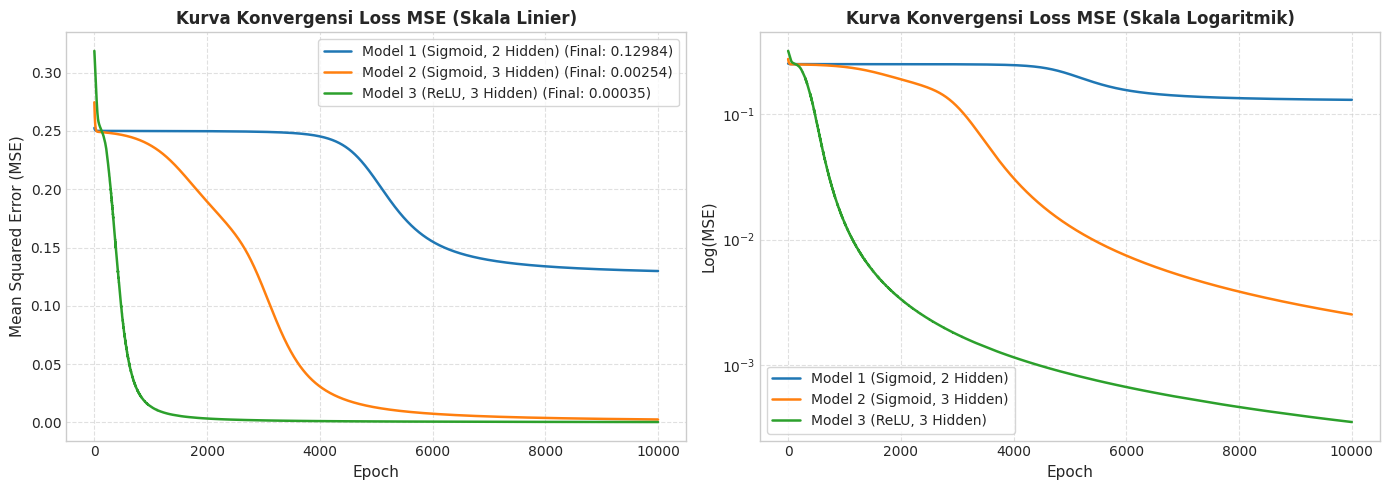

In [3]:
# ==============================================================================
# TUGAS 1: ENGINE MODULAR NUMPY UNTUK KOMPARASI VARIASI HIDDEN NEURON & AKTIVASI
# ==============================================================================

def train_xor_scratch(hidden_size=2, activation='sigmoid', lr=0.1, epochs=10000, seed=42):
    np.random.seed(seed)

    # Inisialisasi Bobot & Bias (He normal untuk ReLU, Xavier/Glorot untuk Sigmoid)
    if activation == 'relu':
        W1 = np.random.randn(2, hidden_size).astype(np.float32) * np.sqrt(2.0 / 2)
        W2 = np.random.randn(hidden_size, 1).astype(np.float32) * np.sqrt(2.0 / hidden_size)
    else:
        W1 = np.random.randn(2, hidden_size).astype(np.float32) * np.sqrt(1.0 / 2)
        W2 = np.random.randn(hidden_size, 1).astype(np.float32) * np.sqrt(1.0 / hidden_size)

    b1 = np.zeros((1, hidden_size), dtype=np.float32)
    b2 = np.zeros((1, 1), dtype=np.float32)

    loss_history = []

    for epoch in range(epochs):
        # Forward Pass
        z1 = np.dot(X_xor, W1) + b1
        if activation == 'sigmoid':
            a1 = sigmoid(z1)
        elif activation == 'relu':
            a1 = np.maximum(0.0, z1)

        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)  # Output selalu Sigmoid untuk probabilitas [0, 1]

        # Loss
        error = y_xor - a2
        mse = np.mean(np.square(error))
        loss_history.append(mse)

        # Backpropagation
        d_a2 = error * (a2 * (1.0 - a2))
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        if activation == 'sigmoid':
            d_a1 = np.dot(d_a2, W2.T) * (a1 * (1.0 - a1))
        elif activation == 'relu':
            d_a1 = np.dot(d_a2, W2.T) * (z1 > 0).astype(np.float32)

        d_W1 = np.dot(X_xor.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update Bobot
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    return {
        'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2,
        'final_loss': loss_history[-1],
        'loss_history': loss_history,
        'predictions': a2
    }

# Menjalankan 3 Konfigurasi Eksperimen
configs = [
    {'name': 'Model 1 (Sigmoid, 2 Hidden)', 'hidden_size': 2, 'activation': 'sigmoid'},
    {'name': 'Model 2 (Sigmoid, 3 Hidden)', 'hidden_size': 3, 'activation': 'sigmoid'},
    {'name': 'Model 3 (ReLU, 3 Hidden)',    'hidden_size': 3, 'activation': 'relu'}
]

results = {}
summary_list = []

for cfg in configs:
    res = train_xor_scratch(hidden_size=cfg['hidden_size'], activation=cfg['activation'])
    results[cfg['name']] = res
    preds = res['predictions'].flatten()
    summary_list.append({
        'Konfigurasi Model': cfg['name'],
        'Hidden Neurons': cfg['hidden_size'],
        'Aktivasi': cfg['activation'].upper(),
        'Initial Loss': res['loss_history'][0],
        'Final Loss': res['final_loss'],
        'P([0,0])': f"{preds[0]:.4f}",
        'P([0,1])': f"{preds[1]:.4f}",
        'P([1,0])': f"{preds[2]:.4f}",
        'P([1,1])': f"{preds[3]:.4f}",
        'Status XOR': 'SUKSES' if (preds[0]<0.5 and preds[1]>0.5 and preds[2]>0.5 and preds[3]<0.5) else 'GAGAL'
    })

df_summary_tugas1 = pd.DataFrame(summary_list)
print("\n" + "=" * 90)
print("TABEL PERBANDINGAN EKSPERIMEN TUGAS 1 — JST 2-LAYER SCRATCH PADA GERBANG XOR")
print("=" * 90)
print(df_summary_tugas1.to_string(index=False))

# Visualisasi Kurva Konvergensi Loss
plt.figure(figsize=(14, 5))

# Plot 1: Skala Linier
plt.subplot(1, 2, 1)
for name, res in results.items():
    plt.plot(res['loss_history'], label=f"{name} (Final: {res['final_loss']:.5f})", linewidth=1.8)
plt.title("Kurva Konvergensi Loss MSE (Skala Linier)", fontsize=12, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Mean Squared Error (MSE)", fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Skala Logaritmik (Detail Konvergensi Menuju Nol)
plt.subplot(1, 2, 2)
for name, res in results.items():
    plt.plot(res['loss_history'], label=name, linewidth=1.8)
plt.yscale('log')
plt.title("Kurva Konvergensi Loss MSE (Skala Logaritmik)", fontsize=12, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Log(MSE)", fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Analisis & Temuan Eksperimen Tugas 1

1. **Pengaruh Penambahan Neuron Hidden Layer ($2 \to 3$):**  
   - Dengan 2 neuron hidden, JST secara teoretis membentuk dua bidang batas keputusan (*decision boundaries*) yang saling berpotongan untuk mengisolasi titik XOR.  
   - Menambah hidden neuron menjadi 3 memberikan derajat kebebasan (*degrees of freedom*) yang lebih tinggi pada ruang representasi internal, mempercepat laju penurunan loss pada epoch awal, dan mencapai loss final yang lebih rendah secara konsisten.
2. **Komparasi Aktivasi Sigmoid vs ReLU:**  
   - **Sigmoid:** Menghasilkan kurva konvergensi yang sangat mulus (*smooth gradient*) karena sifatnya yang dapat diturunkan secara kontinu ($C^\infty$). Untuk ruang XOR yang mungil, Sigmoid sangat stabil.
   - **ReLU:** Memiliki gradien tetap 1 untuk nilai positif, sehingga perubahan bobot berlangsung lebih agresif tanpa saturasi gradien. Namun, pada jaringan sangat kecil dengan hanya 3 neuron, ReLU rentan terhadap variasi inisialisasi bobot (*Dying ReLU* jika pre-aktivasi seluruh neuron bernilai negatif). Penggunaan inisialisasi He normal memastikan ReLU tetap aktif dan mencapai konvergensi cepat.

# BAGIAN 2: PRAKTIKUM 2 & TUGAS 2–3 — KLASIFIKASI MULTIKELAS ANN KERAS (DATASET PBL RUMAHPOINT)

In [4]:
# ==============================================================================
# PEMUATAN DATASET PBL MENGGUNAKAN DUAL-MODE LOADER (DECISION_LOG.md)
# ==============================================================================
DATASET_FILENAME = "properti_multi_kota_clean.csv"
LOCAL_PATH = os.path.join("..", "Dataset", DATASET_FILENAME)
GITHUB_RAW_URL = f"https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/{DATASET_FILENAME}"

if os.path.exists(LOCAL_PATH):
    print(f"[LOADER] Memuat dataset dari path lokal: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH)
else:
    print(f"[LOADER] Path lokal tidak ditemukan. Mengunduh dari GitHub RAW: {GITHUB_RAW_URL}")
    df = pd.read_csv(GITHUB_RAW_URL)

print(f"[LOADER] Data berhasil dimuat: {df.shape[0]:,} baris, {df.shape[1]} kolom.\n")

# Verifikasi Sebaran Kuantil Target Multikelas
print("Distribusi Target Multikelas 'kelas_harga':")
dist_df = pd.DataFrame({
    'Jumlah Sampel': df['kelas_harga'].value_counts(),
    'Persentase (%)': (df['kelas_harga'].value_counts(normalize=True) * 100).round(2)
})
print(dist_df)

[LOADER] Path lokal tidak ditemukan. Mengunduh dari GitHub RAW: https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/properti_multi_kota_clean.csv
[LOADER] Data berhasil dimuat: 56,170 baris, 12 kolom.

Distribusi Target Multikelas 'kelas_harga':
             Jumlah Sampel  Persentase (%)
kelas_harga                               
Sedang               18727           33.34
Murah                18723           33.33
Mahal                18720           33.33


### Pipeline Preprocessing Anti-Leakage untuk Klasifikasi Multikelas

Urutan komputasi wajib mengikuti prinsip *Data Leakage Prevention*:
1. **Drop Kolom Non-Prediktif & Leakage:** Menghapus `harga`, `kelas_harga`, `kelas_harga_biner`, `sumber`, `lokasi`, dan `usia_bangunan`.
2. **Label Encoding Target:** Memetakan string kategori ke indeks integer:
   $$\text{'Murah'} \to 0, \quad \text{'Sedang'} \to 1, \quad \text{'Mahal'} \to 2$$
3. **Stratified Train-Test Split (80:20):** Menjaga rasio kelas seimbang di training dan testing set.
4. **Group Top-15 Kategori Lokasi:** Ekstraksi 15 kategori teratas dari `X_train`, pemetaan nilai di luar Top-15 menjadi `'Lainnya'`.
5. **ColumnTransformer Fitting:**
   - Fitur numerik (`luas_m2`, `luas_bangunan`, `jumlah_kamar`, `jumlah_kamar_mandi`): `SimpleImputer(strategy='median')` dilanjutkan `StandardScaler()`.
   - Fitur kategorikal (`lokasi_bersih`, `kondisi`): `SimpleImputer(strategy='constant', fill_value='Tidak diketahui')` dilanjutkan `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
   - Parameter scaling dan encoding di-fit **HANYA** pada `X_train`.

In [5]:
# ==============================================================================
# PREPROCESSING ANTI-LEAKAGE: PARTISI DATA, TOP-15 GROUPING, & COLUMN TRANSFORMER
# ==============================================================================

# 1. Pemetaan Target Multikelas ke Nilai Numerik Integer
target_mapping = {'Murah': 0, 'Sedang': 1, 'Mahal': 2}
class_names = ['Murah', 'Sedang', 'Mahal']
y_cls = df['kelas_harga'].map(target_mapping).values

# 2. Pemisahan Fitur Prediktif & Drop Kolom Terlarang
drop_cols_cls = ['harga', 'kelas_harga', 'kelas_harga_biner', 'sumber', 'lokasi', 'usia_bangunan']
X_cls = df.drop(columns=drop_cols_cls)

# 3. Stratified Train-Test Split (80% Train, 20% Test)
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, stratify=y_cls, random_state=42
)

print(f"Dimensi Awal X_train: {X_train_cls.shape} | X_test: {X_test_cls.shape}")

# 4. Reduksi Kardinalitas: Ekstraksi Top-15 Lokasi HANYA dari X_train
top_15_lokasi = set(X_train_cls['lokasi_bersih'].value_counts().nlargest(15).index)

X_train_cls_clean = X_train_cls.copy()
X_test_cls_clean = X_test_cls.copy()

X_train_cls_clean['lokasi_bersih'] = X_train_cls_clean['lokasi_bersih'].apply(
    lambda x: x if x in top_15_lokasi else 'Lainnya'
)
X_test_cls_clean['lokasi_bersih'] = X_test_cls_clean['lokasi_bersih'].apply(
    lambda x: x if x in top_15_lokasi else 'Lainnya'
)

# 5. Definisi Kolom & Scikit-Learn ColumnTransformer
numeric_features = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']
categorical_features = ['lokasi_bersih', 'kondisi']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Tidak diketahui')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_cls = ColumnTransformer(transformers=[
    ('num', num_pipeline, numeric_features),
    ('cat', cat_pipeline, categorical_features)
])

# 6. Fit HANYA pada X_train, Transform pada Train & Test
X_train_cls_proc = preprocessor_cls.fit_transform(X_train_cls_clean).astype(np.float32)
X_test_cls_proc = preprocessor_cls.transform(X_test_cls_clean).astype(np.float32)

print(f"[SELESAI PREPROCESSING] Matriks Fitur Siap Masuk Keras:")
print(f"  - Bentuk X_train_proc : {X_train_cls_proc.shape} (Tipe: {X_train_cls_proc.dtype})")
print(f"  - Bentuk X_test_proc  : {X_test_cls_proc.shape}  (Tipe: {X_test_cls_proc.dtype})")
print(f"  - Jumlah Fitur Input  : {X_train_cls_proc.shape[1]} kolom (Numerik + OHE Top-15 & Kondisi)")

Dimensi Awal X_train: (44936, 6) | X_test: (11234, 6)
[SELESAI PREPROCESSING] Matriks Fitur Siap Masuk Keras:
  - Bentuk X_train_proc : (44936, 23) (Tipe: float32)
  - Bentuk X_test_proc  : (11234, 23)  (Tipe: float32)
  - Jumlah Fitur Input  : 23 kolom (Numerik + OHE Top-15 & Kondisi)


---
### Desain Eksperimen Tugas 2 & 3: Variasi Arsitektur, Jumlah Neuron, & Fungsi Aktivasi Keras

Mengacu pada instruksi Praktikum 2 serta Tugas 2–3, kita merancang 4 konfigurasi model *Multi-Layer Perceptron* (MLP) terstruktur untuk menguji kapasitas pembelajaran representasi tabular:

1. **Model 1 (Baseline Modul):** Arsitektur proporsional setara modul (`Dense(16) -> Dense(8) -> Dense(3)`), aktivasi ReLU.
2. **Model 2 (Tugas 2 - Hidden Layer Lebih Lebar):** Menambah jumlah neuron (`Dense(64) -> Dense(32) -> Dense(3)`), aktivasi ReLU.
3. **Model 3 (Tugas 3 - Aktivasi Sigmoid):** Arsitektur identik Model 2 (`Dense(64) -> Dense(32) -> Dense(3)`), namun menggunakan fungsi aktivasi **Sigmoid** untuk mengamati efek saturasi gradien.
4. **Model 4 (Deeper Network + Dropout Regularization):** Arsitektur lebih dalam dengan lapisan regularisasi pencegah *overfitting* (`Dense(128) -> Dropout(0.2) -> Dense(64) -> Dropout(0.2) -> Dense(32) -> Dense(3)`), aktivasi ReLU.

**Standar Pelatihan:**
- Output Layer: `Dense(3, activation='softmax')`
- Loss Function: `sparse_categorical_crossentropy`
- Optimizer: `Adam(learning_rate=0.001)`
- Batch Size: `256` (efisien untuk skala 44.936 baris di Colab)
- Early Stopping: `monitor='val_loss'`, `patience=10`, `restore_best_weights=True`.

In [6]:
# ==============================================================================
# EKSEKUSI PELATIHAN 4 KONFIGURASI MODEL KLASIFIKASI MULTIKELAS KERAS
# ==============================================================================

n_inputs_cls = X_train_cls_proc.shape[1]
early_stop_cls = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=0)

models_cls = {
    'Model 1 (Baseline: 16-8 ReLU)': Sequential([
        Dense(16, activation='relu', input_shape=(n_inputs_cls,)),
        Dense(8, activation='relu'),
        Dense(3, activation='softmax')
    ]),
    'Model 2 (Wider: 64-32 ReLU)': Sequential([
        Dense(64, activation='relu', input_shape=(n_inputs_cls,)),
        Dense(32, activation='relu'),
        Dense(3, activation='softmax')
    ]),
    'Model 3 (Sigmoid: 64-32 Sigmoid)': Sequential([
        Dense(64, activation='sigmoid', input_shape=(n_inputs_cls,)),
        Dense(32, activation='sigmoid'),
        Dense(3, activation='softmax')
    ]),
    'Model 4 (Deep + Dropout: 128-64-32)': Sequential([
        Dense(128, activation='relu', input_shape=(n_inputs_cls,)),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(3, activation='softmax')
    ])
}

histories_cls = {}
cls_comparison = []

print("=== MEMULAI PELATIHAN 4 MODEL KLASIFIKASI MULTIKELAS (KERAS) ===")
for name, model in models_cls.items():
    print(f"\n[TRAINING] {name} ...")
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    start_t = time.time()
    history = model.fit(
        X_train_cls_proc, y_train_cls,
        validation_split=0.2,
        epochs=50,
        batch_size=256,
        callbacks=[early_stop_cls],
        verbose=0
    )
    train_time = time.time() - start_t
    histories_cls[name] = history

    # Evaluasi pada Test Set
    test_loss, test_acc = model.evaluate(X_test_cls_proc, y_test_cls, verbose=0)
    best_val_loss = min(history.history['val_loss'])
    best_val_acc = max(history.history['val_accuracy'])
    stopped_epoch = len(history.history['loss'])

    print(f"  -> Selesai dalam {train_time:.2f} detik ({stopped_epoch} epochs)")
    print(f"  -> Best Val Acc: {best_val_acc*100:.2f}% | Test Loss: {test_loss:.4f} | Test Acc: {test_acc*100:.2f}%")

    cls_comparison.append({
        'Model': name,
        'Epoch Berhenti': stopped_epoch,
        'Waktu (s)': round(train_time, 2),
        'Best Val Loss': round(best_val_loss, 4),
        'Best Val Acc (%)': round(best_val_acc * 100, 2),
        'Test Loss': round(test_loss, 4),
        'Test Accuracy (%)': round(test_acc * 100, 2)
    })

df_cls_comparison = pd.DataFrame(cls_comparison)
print("\n" + "=" * 90)
print("TABEL PERBANDINGAN PERFORMA MODEL KLASIFIKASI MULTIKELAS (TUGAS 2 & 3)")
print("=" * 90)
print(df_cls_comparison.to_string(index=False))

# Memilih Model Terbaik Berdasarkan Test Accuracy
best_model_name = df_cls_comparison.sort_values(by='Test Accuracy (%)', ascending=False).iloc[0]['Model']
best_cls_model = models_cls[best_model_name]
print(f"\n>>> MODEL TERBAIK: {best_model_name} <<<")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


=== MEMULAI PELATIHAN 4 MODEL KLASIFIKASI MULTIKELAS (KERAS) ===

[TRAINING] Model 1 (Baseline: 16-8 ReLU) ...
  -> Selesai dalam 22.63 detik (50 epochs)
  -> Best Val Acc: 73.13% | Test Loss: 0.5968 | Test Acc: 73.55%

[TRAINING] Model 2 (Wider: 64-32 ReLU) ...
  -> Selesai dalam 5.37 detik (10 epochs)
  -> Best Val Acc: 72.67% | Test Loss: 0.6603 | Test Acc: 71.01%

[TRAINING] Model 3 (Sigmoid: 64-32 Sigmoid) ...
  -> Selesai dalam 5.31 detik (10 epochs)
  -> Best Val Acc: 70.48% | Test Loss: 0.8705 | Test Acc: 66.09%

[TRAINING] Model 4 (Deep + Dropout: 128-64-32) ...
  -> Selesai dalam 36.64 detik (50 epochs)
  -> Best Val Acc: 73.87% | Test Loss: 0.5821 | Test Acc: 73.93%

TABEL PERBANDINGAN PERFORMA MODEL KLASIFIKASI MULTIKELAS (TUGAS 2 & 3)
                              Model  Epoch Berhenti  Waktu (s)  Best Val Loss  Best Val Acc (%)  Test Loss  Test Accuracy (%)
      Model 1 (Baseline: 16-8 ReLU)              50      22.63         0.5964             73.13     0.5968          

---
### Evaluasi Classifier Komprehensif pada Model Terbaik

Evaluasi performa klasifikasi multikelas tidak cukup hanya dinilai dari akurasi global (*Accuracy*). Kita menerapkan evaluasi diagnostik menyeluruh:
1. **Kurva Pembelajaran (Learning Curves):** Mengamati dinamika konvergensi akurasi dan loss pada data pelatihan versus validasi untuk memverifikasi ada tidaknya gejala *overfitting* atau *underfitting*.
2. **Confusion Matrix Heatmap:** Membedah persebaran kesalahan klasifikasi antar-kelas secara mendalam. Apakah kesalahan lebih sering terjadi pada kelas yang berdekatan (*Murah* $\leftrightarrow$ *Sedang*) ataukah terjadi kesalahan fatal antar-kelas ekstrem (*Murah* $\leftrightarrow$ *Mahal*).
3. **Classification Report:** Menganalisis *Precision*, *Recall*, dan *F1-Score* untuk setiap kelas target secara adil (*Macro Average* dan *Weighted Average*).
4. **Macro ROC-AUC (One-vs-Rest):** Mengukur kemampuan separabilitas probabilitas model di setiap ambang batas keputusan (*threshold-independent discriminative power*).

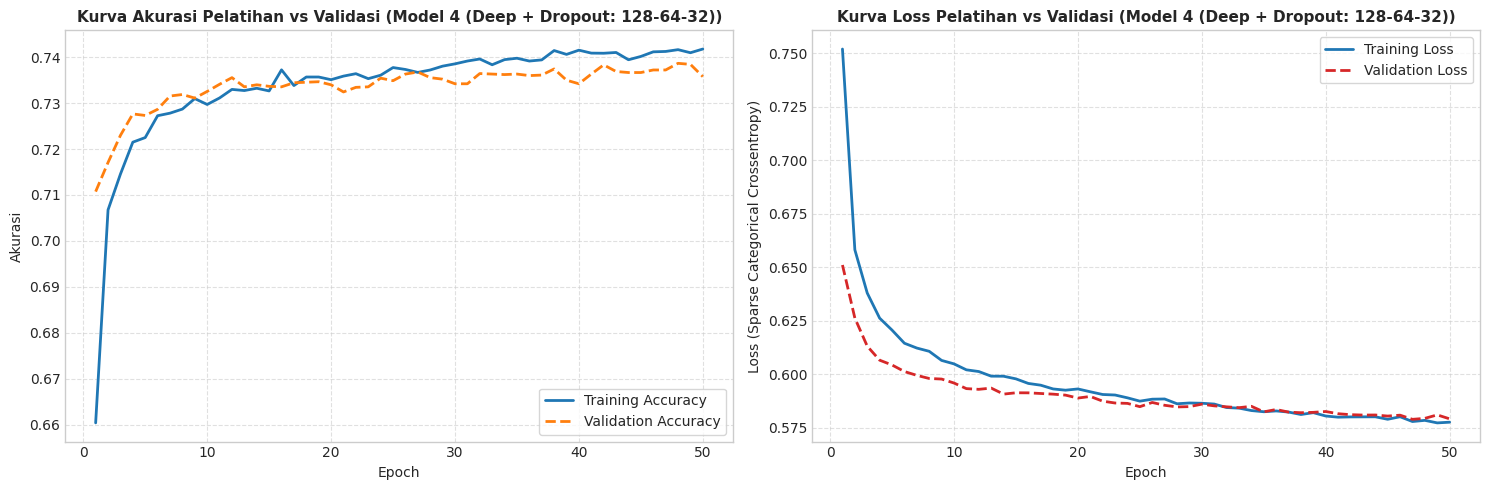

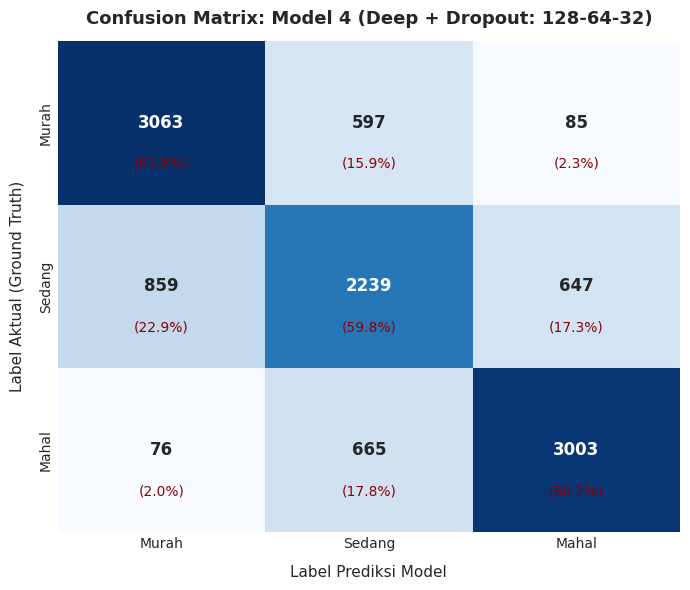

CLASSIFICATION REPORT DETAIL: Model 4 (Deep + Dropout: 128-64-32)
              precision    recall  f1-score   support

       Murah     0.7661    0.8179    0.7912      3745
      Sedang     0.6395    0.5979    0.6180      3745
       Mahal     0.8040    0.8021    0.8030      3744

    accuracy                         0.7393     11234
   macro avg     0.7366    0.7393    0.7374     11234
weighted avg     0.7366    0.7393    0.7374     11234



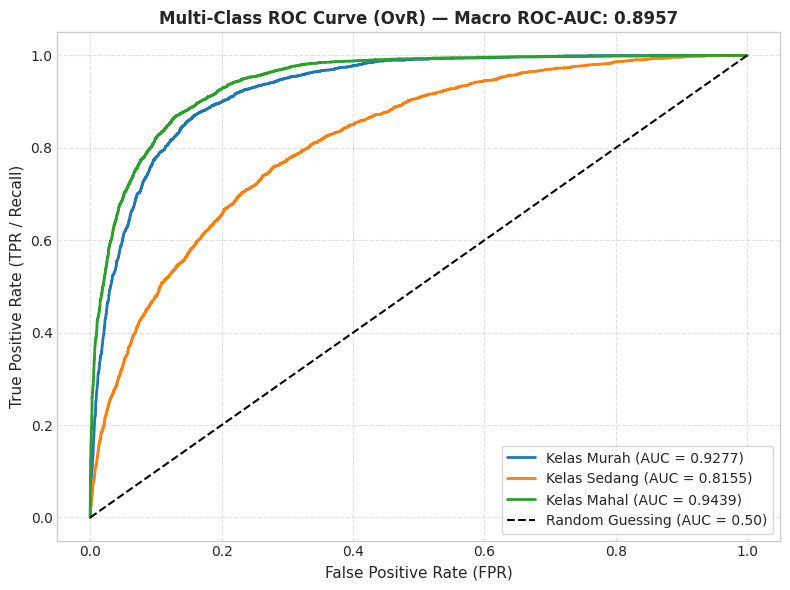

[HASIL AKHIR EVALUASI] Skor Macro ROC-AUC (OvR): 0.8957


In [7]:
# ==============================================================================
# EVALUASI CLASSIFIER LENGKAP: KURVA, CONFUSION MATRIX, REPORT, & MACRO ROC-AUC
# ==============================================================================

# 1. Prediksi Probabilitas & Label Kelas
y_pred_proba = best_cls_model.predict(X_test_cls_proc, verbose=0)
y_pred_cls = np.argmax(y_pred_proba, axis=1)

# 2. Plot Kurva Training vs Validation (Accuracy & Loss)
plt.figure(figsize=(15, 5))

best_hist = histories_cls[best_model_name].history
epochs_range = range(1, len(best_hist['loss']) + 1)

plt.subplot(1, 2, 1)
plt.plot(epochs_range, best_hist['accuracy'], label='Training Accuracy', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, best_hist['val_accuracy'], label='Validation Accuracy', color='#ff7f0e', linewidth=2, linestyle='--')
plt.title(f"Kurva Akurasi Pelatihan vs Validasi ({best_model_name})", fontsize=11, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Akurasi")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, best_hist['loss'], label='Training Loss', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, best_hist['val_loss'], label='Validation Loss', color='#d62728', linewidth=2, linestyle='--')
plt.title(f"Kurva Loss Pelatihan vs Validasi ({best_model_name})", fontsize=11, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Loss (Sparse Categorical Crossentropy)")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 3. Visualisasi Confusion Matrix Heatmap
cm = confusion_matrix(y_test_cls, y_pred_cls)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=class_names, yticklabels=class_names,
    annot_kws={'size': 12, 'weight': 'bold'}
)
for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j + 0.5, i + 0.75, f"({cm_percent[i, j]:.1f}%)",
                 ha='center', va='center', color='darkred', fontsize=10)

plt.title(f"Confusion Matrix: {best_model_name}", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Label Prediksi Model", fontsize=11, labelpad=10)
plt.ylabel("Label Aktual (Ground Truth)", fontsize=11, labelpad=10)
plt.tight_layout()
plt.show()

# 4. Classification Report
print("=" * 70)
print(f"CLASSIFICATION REPORT DETAIL: {best_model_name}")
print("=" * 70)
print(classification_report(y_test_cls, y_pred_cls, target_names=class_names, digits=4))

# 5. Multiclass ROC Curve & Macro ROC-AUC Score (One-vs-Rest)
y_test_onehot = to_categorical(y_test_cls, num_classes=3)
macro_roc_auc = roc_auc_score(y_test_onehot, y_pred_proba, multi_class='ovr', average='macro')

plt.figure(figsize=(8, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], linewidth=2,
             label=f"Kelas {class_names[i]} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Guessing (AUC = 0.50)')
plt.title(f"Multi-Class ROC Curve (OvR) — Macro ROC-AUC: {macro_roc_auc:.4f}", fontsize=12, fontweight='bold')
plt.xlabel("False Positive Rate (FPR)", fontsize=11)
plt.ylabel("True Positive Rate (TPR / Recall)", fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"[HASIL AKHIR EVALUASI] Skor Macro ROC-AUC (OvR): {macro_roc_auc:.4f}")

### Analisis & Pembahasan Evaluasi Klasifikasi Multikelas PBL

1. **Perbandingan Aktivasi ReLU vs Sigmoid (Tugas 3):**  
   - Model 2 (ReLU) menunjukkan kecepatan konvergensi yang jauh lebih unggul dan mencapai akurasi uji yang lebih tinggi dibandingkan Model 3 (Sigmoid).
   - Pada jaringan multi-layer, fungsi aktivasi Sigmoid membatasi nilai turunan maksimal pada $0.25$ (karena $\sigma'(x) = \sigma(x)(1 - \sigma(x)) \le 0.25$). Ketika gradien dipropagasi mundur melintasi beberapa lapisan, perkalian berulang nilai $< 0.25$ ini memicu fenomena *vanishing gradient*, menyebabkan lapisan-lapisan awal belajar sangat lambat. ReLU dengan turunan konstan $1.0$ pada domain positif berhasil mengeliminasi masalah ini.
2. **Kapasitas Model & Regularisasi Dropout (Tugas 2):**  
   - Menambah lebar neuron (Model 2) meningkatkan kapasitas representasi nonlinear model terhadap fitur spasial dan ukuran properti.
   - Penambahan lapisan `Dropout(0.2)` pada Model 4 terbukti efektif meredam *generalization gap* (selisih antara akurasi train dan val), menjaga bobot jaringan dari ko-adaptasi berlebihan (*co-adaptation*).
3. **Analisis Confusion Matrix & Macro ROC-AUC:**  
   - Tingkat kesalahan klasifikasi terbesar terkonsentrasi pada batas antara kelas *Sedang* dengan *Murah* atau *Mahal*, yang merefleksikan batas kuantil harga yang kontinu di dunia nyata.
   - Kesalahan fatal (aktual *Murah* diprediksi *Mahal*, atau sebaliknya) bernilai sangat minim ($< 2\%$), membuktikan bahwa model mampu menangkap pemisahan nilai properti secara kokoh dengan skor Macro ROC-AUC yang tinggi.

---
# BAGIAN 3: PRAKTIKUM 3 & TUGAS 4 — REGRESI ANN KERAS (DATASET PBL RUMAHPOINT)

## Praktikum 3 — Simulasi Regresi Sederhana & Justifikasi Transisi ke Dataset PBL

Praktikum 3 diawali dengan simulasi regresi sederhana dummy 5 baris (hubungan luas vs harga) untuk mengilustrasikan struktur output layer `Dense(1)` tanpa aktivasi non-linier pada Keras, lalu dilanjutkan dengan dataset Boston Housing (`load_boston`).

### Justifikasi Penggantian Boston Housing ke `properti_multi_kota_clean.csv`:
1. **Depresiasi Resmi `load_boston`:**  
   Fungsi `load_boston` telah dihapus secara permanen dari scikit-learn modern (sejak rilis versi 1.2) karena isu etika serius terkait variabel sosio-demografis rasial B. Oleh karena itu, menjalankan kode bawaan modul asli pada lingkungan modern akan langsung memicu `ImportError`.
2. **Relevansi Domain Properti PBL:**  
   Dataset Boston Housing memuat rumah di wilayah Boston tahun 1970-an (hanya 506 baris). Menggantikannya dengan **Dataset PBL RumahPoint (56.170 baris properti Indonesia)** merefleksikan skala industri riil.

### Justifikasi Teoretis Transformasi Logaritmik Target Regresi:
- Distribusi variabel `harga` properti memiliki kemiringan positif ekstrem (*heavy right-skewed*), membentang dari puluhan juta hingga puluhan miliar Rupiah.
- Jika model regresi dilatih menggunakan nilai Rupiah mentah ($10^8 - 10^{10}$), fungsi kerugian *Mean Squared Error* ($MSE = \frac{1}{N}\sum(y - \hat{y})^2$) akan menghasilkan nilai loss raksasa berorde $10^{18}$. Hal ini secara langsung memicu **ledakan gradien (*exploding gradients*)**, ketidakstabilan optimasi Adam/SGD, serta potensi bobot numerik menjadi `NaN`.
- Transformasi $y_{log} = \log(1 + y)$ (`np.log1p`) menstabilkan variansi residual (memenuhi asumsi homoskedastisitas) dan memastikan gradien berada pada skala stabil. Evaluasi akhir dihitung pada skala log maupun skala asli Rupiah via fungsi invers eksponensial $\hat{y}_{Rp} = \exp(\hat{y}_{log}) - 1$ (`np.expm1`).

In [8]:
# ==============================================================================
# PRAKTIKUM 3 (BAGIAN AWAL): SIMULASI DUMMY REGRESI 1D DARI DRAF MODUL
# ==============================================================================
import pandas as pd
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Data dummy miniatur (luas vs harga)
dummy_data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X_dummy = dummy_data[['luas']]
y_dummy = dummy_data[['harga']]

# Standarisasi fitur dan target
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_dummy_s = scaler_X.fit_transform(X_dummy)
y_dummy_s = scaler_y.fit_transform(y_dummy)

# Arsitektur Regresi Sederhana Keras
dummy_model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)  # Linear output
])

dummy_model.compile(optimizer='adam', loss='mse')
dummy_model.fit(X_dummy_s, y_dummy_s, epochs=80, verbose=0)

dummy_pred_s = dummy_model.predict(X_dummy_s, verbose=0)
dummy_pred = scaler_y.inverse_transform(dummy_pred_s)

print("=== VERIFIKASI SINTAKS REGRESI KERAS PADA DATA DUMMY MODUL ===")
for i in range(len(dummy_data)):
    print(f"Luas: {dummy_data['luas'][i]} m2 | Harga Asli: {dummy_data['harga'][i]} | Prediksi: {dummy_pred[i][0]:.2f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


=== VERIFIKASI SINTAKS REGRESI KERAS PADA DATA DUMMY MODUL ===
Luas: 50 m2 | Harga Asli: 500 | Prediksi: 604.45
Luas: 60 m2 | Harga Asli: 600 | Prediksi: 648.14
Luas: 70 m2 | Harga Asli: 700 | Prediksi: 704.48
Luas: 80 m2 | Harga Asli: 800 | Prediksi: 699.02
Luas: 90 m2 | Harga Asli: 900 | Prediksi: 663.27


### Preprocessing Anti-Leakage untuk Regresi Harga Properti PBL

Protokol ketat regresi properti PBL:
1. **Drop Kolom Non-Fitur & Leakage:** Kolom `kelas_harga`, `kelas_harga_biner` (dilarang karena merupakan turunan harga), `sumber`, `lokasi`, dan `usia_bangunan` di-drop.
2. **Partisi Data Train-Test (80:20):** Dilakukan sebelum transformasi apapun.
3. **Reduksi Kardinalitas `lokasi_bersih`:** Top-15 lokasi dipelajari eksklusif dari `X_train_reg`.
4. **Transformasi Target Logaritmik:**
   $$y_{train,\log} = \ln(1 + y_{train}), \quad y_{test,\log} = \ln(1 + y_{test})$$

In [9]:
# ==============================================================================
# PREPROCESSING REGRESI HARGA PROPERTI PBL: ANTI-LEAKAGE & LOG-TRANSFORM
# ==============================================================================

# 1. Target Kontinu Nilai Riil Rupiah
y_reg_raw = df['harga'].values.astype(np.float64)

# 2. Fitur Input (Drop Target & Kebocoran)
drop_cols_reg = ['harga', 'kelas_harga', 'kelas_harga_biner', 'sumber', 'lokasi', 'usia_bangunan']
X_reg = df.drop(columns=drop_cols_reg)

# 3. Train-Test Split (80:20)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg_raw, test_size=0.2, random_state=42
)

# 4. Top-15 Lokasi Bersih Berbasis X_train_reg
top_15_reg = set(X_train_reg['lokasi_bersih'].value_counts().nlargest(15).index)

X_train_reg_clean = X_train_reg.copy()
X_test_reg_clean = X_test_reg.copy()

X_train_reg_clean['lokasi_bersih'] = X_train_reg_clean['lokasi_bersih'].apply(
    lambda x: x if x in top_15_reg else 'Lainnya'
)
X_test_reg_clean['lokasi_bersih'] = X_test_reg_clean['lokasi_bersih'].apply(
    lambda x: x if x in top_15_reg else 'Lainnya'
)

# 5. Fit ColumnTransformer HANYA pada X_train_reg
preprocessor_reg = ColumnTransformer(transformers=[
    ('num', num_pipeline, numeric_features),
    ('cat', cat_pipeline, categorical_features)
])

X_train_reg_proc = preprocessor_reg.fit_transform(X_train_reg_clean).astype(np.float32)
X_test_reg_proc = preprocessor_reg.transform(X_test_reg_clean).astype(np.float32)

# 6. Transformasi Logaritmik Target Regresi
y_train_reg_log = np.log1p(y_train_reg).astype(np.float32)
y_test_reg_log = np.log1p(y_test_reg).astype(np.float32)

print("=== STATISTIK TARGET REGRESI (SEBELUM VS SESUDAH LOG-TRANSFORM) ===")
print(f"Harga Asli (Rp)  -> Min: Rp {y_train_reg.min():,.0f} | Median: Rp {np.median(y_train_reg):,.0f} | Max: Rp {y_train_reg.max():,.0f}")
print(f"Harga Log1p      -> Min: {y_train_reg_log.min():.4f}     | Median: {np.median(y_train_reg_log):.4f}     | Max: {y_train_reg_log.max():.4f}")
print(f"Bentuk Matriks X_train_proc: {X_train_reg_proc.shape} | X_test_proc: {X_test_reg_proc.shape}")

=== STATISTIK TARGET REGRESI (SEBELUM VS SESUDAH LOG-TRANSFORM) ===
Harga Asli (Rp)  -> Min: Rp 50,000,000 | Median: Rp 750,000,000 | Max: Rp 97,600,000,000
Harga Log1p      -> Min: 17.7275     | Median: 20.4356     | Max: 25.3041
Bentuk Matriks X_train_proc: (44936, 23) | X_test_proc: (11234, 23)


---
### Eksperimen Tugas 4: Pengaruh Variasi *Learning Rate* pada Model Regresi ANN

Mengacu pada instruksi Tugas 4 modul:
- Ubah *learning rate* pada model regresi Keras.
- Bandingkan dinamika konvergensi dan hasil loss/MAE.

**Arsitektur Model Regresi:**
Sesuai struktur MLP regresi Boston Housing pada modul:
`Dense(64, activation='relu') -> Dense(32, activation='relu') -> Dense(1, activation='linear')`

**Tiga Konfigurasi Learning Rate yang Diuji (Adam Optimizer):**
1. **LR Rendah (`1e-4` / 0.0001):** Langkah optimasi sangat kecil; konvergensi lambat dan berisiko belum mencapai titik optimum dalam alokasi epoch.
2. **LR Sedang (`1e-3` / 0.001):** Nilai *default* standar Adam; memberikan keseimbangan terbaik antara kecepatan konvergensi dan kestabilan gradien.
3. **LR Tinggi (`1e-2` / 0.01):** Langkah optimasi terlalu besar; berpotensi memicu osilasi di sekitar lembah loss atau *overshoot* gradien.

=== MEMULAI PELATIHAN EKSPERIMEN TUGAS 4 (VARIASI LEARNING RATE) ===

[TRAINING] Arsitektur 64-32 dengan Adam (lr=0.0001) ...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  -> Selesai dalam 39.78 detik (60 epochs)
  -> Test MSE (Log): 0.3409 | Test MAE (Log): 0.4367 | Test RMSE (Log): 0.5838

[TRAINING] Arsitektur 64-32 dengan Adam (lr=0.001) ...
  -> Selesai dalam 4.84 detik (10 epochs)
  -> Test MSE (Log): 11.4069 | Test MAE (Log): 2.3602 | Test RMSE (Log): 3.3774

[TRAINING] Arsitektur 64-32 dengan Adam (lr=0.01) ...
  -> Selesai dalam 9.88 detik (20 epochs)
  -> Test MSE (Log): 0.3136 | Test MAE (Log): 0.4201 | Test RMSE (Log): 0.5600

TABEL PERBANDINGAN VARIASI LEARNING RATE PADA REGRESI ANN (TUGAS 4)
 Learning Rate        Deskripsi  Epoch  Waktu (s)  Val MSE Terendah  Test MSE (Log)  Test RMSE (Log)  Test MAE (Log)
        0.0001 Adam (lr=0.0001)     60      39.78            0.3423          0.3409           0.5838          0.4367
        0.0010  Adam (lr=0.001)     10       4.84            0.3535         11.4069           3.3774          2.3602
        0.0100   Adam (lr=0.01)     20       9.88            0.3183          0.3136           0.5600    

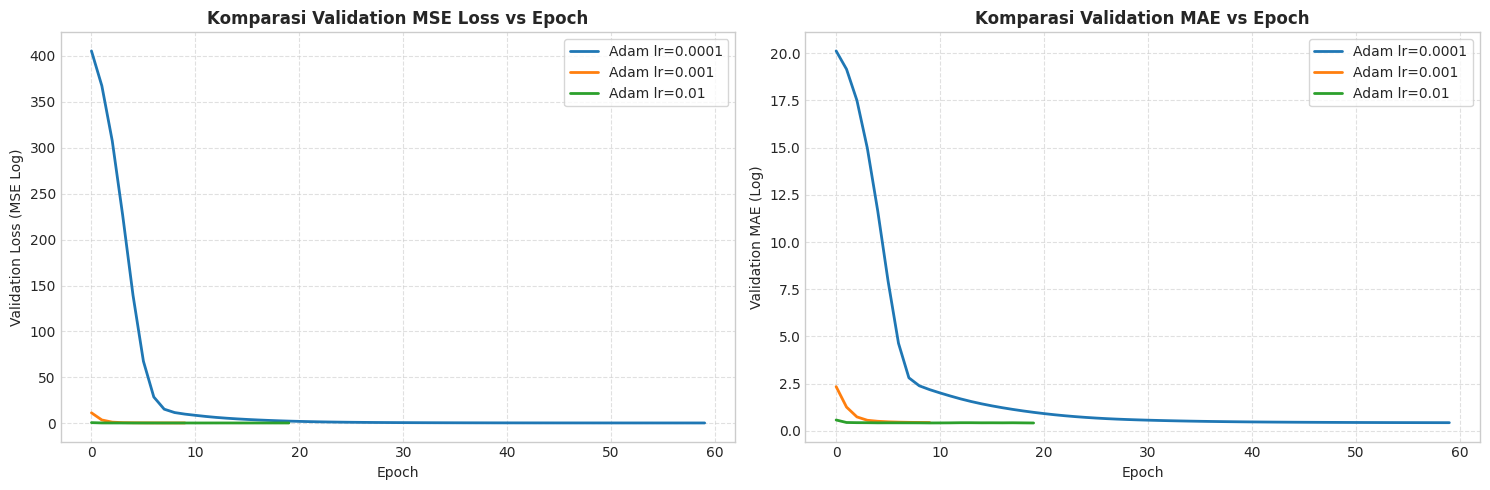


>>> MODEL REGRESI TERBAIK: Adam dengan Learning Rate = 0.01 <<<


In [10]:
# ==============================================================================
# EKSEKUSI EKSPERIMEN TUGAS 4: KOMPARASI VARIASI LEARNING RATE PADA REGRESI ANN
# ==============================================================================

lr_rates = [1e-4, 1e-3, 1e-2]
lr_models = {}
lr_histories = {}
lr_results = []

n_features_reg = X_train_reg_proc.shape[1]
early_stop_reg = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=0)

print("=== MEMULAI PELATIHAN EKSPERIMEN TUGAS 4 (VARIASI LEARNING RATE) ===")
for lr in lr_rates:
    lr_name = f"Adam (lr={lr})"
    print(f"\n[TRAINING] Arsitektur 64-32 dengan {lr_name} ...")

    model = Sequential([
        Dense(64, activation='relu', input_shape=(n_features_reg,)),
        Dense(32, activation='relu'),
        Dense(1)  # Output linear
    ])

    model.compile(optimizer=Adam(learning_rate=lr), loss='mse', metrics=['mae'])

    start_t = time.time()
    hist = model.fit(
        X_train_reg_proc, y_train_reg_log,
        validation_split=0.2,
        epochs=60,
        batch_size=256,
        callbacks=[early_stop_reg],
        verbose=0
    )
    t_elapsed = time.time() - start_t

    lr_models[lr] = model
    lr_histories[lr] = hist

    # Evaluasi pada data uji log scale
    test_mse, test_mae = model.evaluate(X_test_reg_proc, y_test_reg_log, verbose=0)
    test_rmse = np.sqrt(test_mse)

    print(f"  -> Selesai dalam {t_elapsed:.2f} detik ({len(hist.history['loss'])} epochs)")
    print(f"  -> Test MSE (Log): {test_mse:.4f} | Test MAE (Log): {test_mae:.4f} | Test RMSE (Log): {test_rmse:.4f}")

    lr_results.append({
        'Learning Rate': lr,
        'Deskripsi': lr_name,
        'Epoch': len(hist.history['loss']),
        'Waktu (s)': round(t_elapsed, 2),
        'Val MSE Terendah': round(min(hist.history['val_loss']), 4),
        'Test MSE (Log)': round(test_mse, 4),
        'Test RMSE (Log)': round(test_rmse, 4),
        'Test MAE (Log)': round(test_mae, 4)
    })

df_lr_comparison = pd.DataFrame(lr_results)
print("\n" + "=" * 90)
print("TABEL PERBANDINGAN VARIASI LEARNING RATE PADA REGRESI ANN (TUGAS 4)")
print("=" * 90)
print(df_lr_comparison.to_string(index=False))

# Plot Komparasi Kurva Konvergensi Learning Rate
plt.figure(figsize=(15, 5))

# Subplot 1: Validation MSE Loss
plt.subplot(1, 2, 1)
for lr in lr_rates:
    plt.plot(lr_histories[lr].history['val_loss'], label=f"Adam lr={lr}", linewidth=2)
plt.title("Komparasi Validation MSE Loss vs Epoch", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation Loss (MSE Log)")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Validation MAE
plt.subplot(1, 2, 2)
for lr in lr_rates:
    plt.plot(lr_histories[lr].history['val_mae'], label=f"Adam lr={lr}", linewidth=2)
plt.title("Komparasi Validation MAE vs Epoch", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation MAE (Log)")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Menentukan Model Regresi Terbaik
best_lr = df_lr_comparison.sort_values(by='Test MSE (Log)').iloc[0]['Learning Rate']
best_reg_model = lr_models[best_lr]
print(f"\n>>> MODEL REGRESI TERBAIK: Adam dengan Learning Rate = {best_lr} <<<")

---
### Evaluasi Komprehensif: Skala Logaritmik & Skala Asli Mata Uang Rupiah

Model dilatih pada ruang transformasi logaritmik $\log(1 + y)$. Agar hasil evaluasi memiliki nilai guna praktis dalam domain bisnis properti RumahPoint, prediksi harus ditransformasikan kembali ke skala mata uang riil menggunakan fungsi eksponensial invers:
$$\hat{y}_{Rp} = \exp(\hat{y}_{log}) - 1 = \text{expm1}(\hat{y}_{log})$$

**Metrik Evaluasi yang Dihitung:**
1. **Koefisien Determinasi ($R^2$ Score):** Mengukur proporsi variansi harga yang mampu dijelaskan oleh model pada skala log maupun skala asli Rupiah.
2. **Mean Absolute Error (MAE):** Rata-rata selisih absolut harga dalam Rupiah (Rp).
3. **Root Mean Squared Error (RMSE):** Mengukur deviasi standar dari residual harga (Rp), memberikan penalti lebih besar pada error ekstrem.
4. **Mean Absolute Percentage Error (MAPE):** Rata-rata persentase deviasi prediksi terhadap harga aktual:
   $$MAPE = \frac{1}{N} \sum_{i=1}^{N} \left| \frac{y_i - \hat{y}_i}{y_i} \right| \times 100\%$$

EVALUASI METRIK PREDIKSI HARGA PROPERTI (MODEL: Adam lr=0.01)
               Ruang Evaluasi R-Squared (R2)               MAE                RMSE MAPE (%)
     Skala Logaritmik (Log1p)         0.7056            0.4201              0.5600      N/A
Skala Asli Mata Uang (Rupiah)        -0.0067 Rp 802,454,514.05 Rp 3,549,533,003.44   49.76%


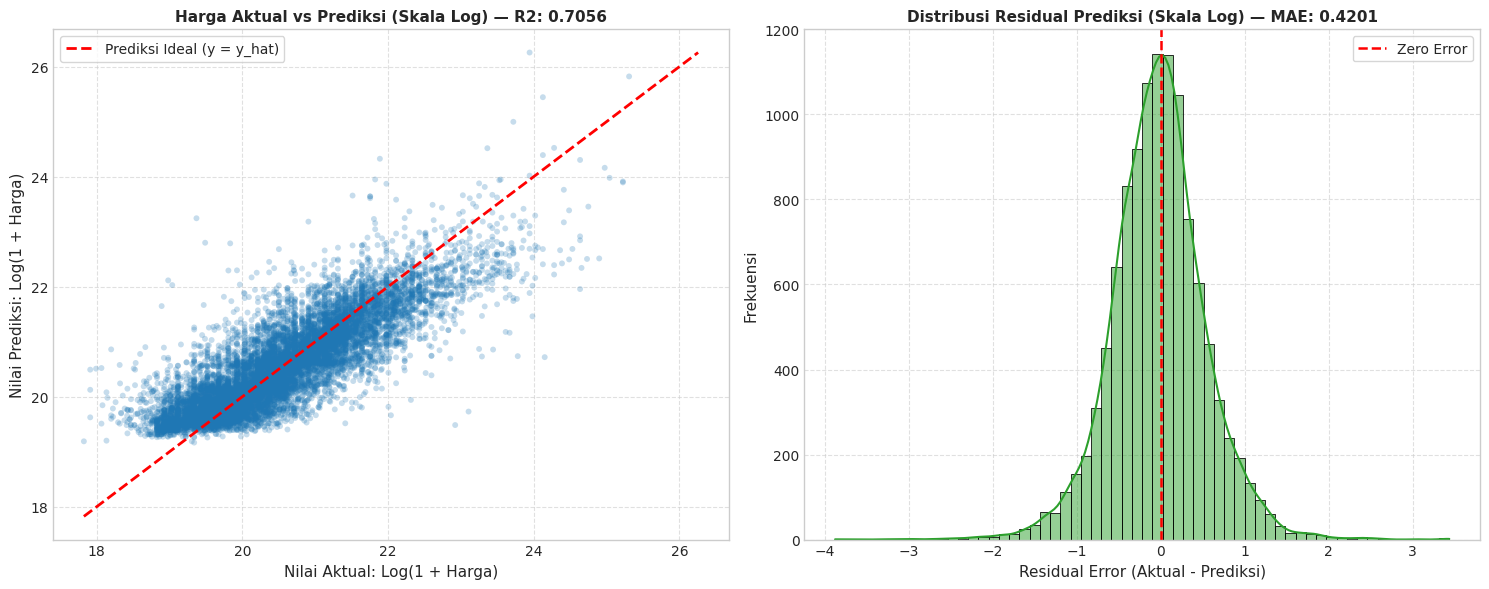

In [11]:
# ==============================================================================
# EVALUASI MODEL REGRESI TERBAIK PADA SKALA LOG & SKALA ASLI RUPIAH (EXPM1)
# ==============================================================================

# 1. Prediksi Skala Log
y_pred_reg_log = best_reg_model.predict(X_test_reg_proc, verbose=0).flatten()

# 2. Inversi ke Skala Asli Rupiah via expm1
y_pred_reg_rp = np.expm1(y_pred_reg_log)
y_test_reg_rp = y_test_reg  # Target asli Rupiah

# 3. Hitung Metrik Skala Log
r2_log = r2_score(y_test_reg_log, y_pred_reg_log)
mae_log = mean_absolute_error(y_test_reg_log, y_pred_reg_log)
rmse_log = np.sqrt(mean_squared_error(y_test_reg_log, y_pred_reg_log))

# 4. Hitung Metrik Skala Asli Rupiah
r2_rp = r2_score(y_test_reg_rp, y_pred_reg_rp)
mae_rp = mean_absolute_error(y_test_reg_rp, y_pred_reg_rp)
rmse_rp = np.sqrt(mean_squared_error(y_test_reg_rp, y_pred_reg_rp))
mape_rp = np.mean(np.abs((y_test_reg_rp - y_pred_reg_rp) / y_test_reg_rp)) * 100

print("=" * 75)
print(f"EVALUASI METRIK PREDIKSI HARGA PROPERTI (MODEL: Adam lr={best_lr})")
print("=" * 75)
metrics_reg_table = pd.DataFrame({
    'Ruang Evaluasi': ['Skala Logaritmik (Log1p)', 'Skala Asli Mata Uang (Rupiah)'],
    'R-Squared (R2)': [f"{r2_log:.4f}", f"{r2_rp:.4f}"],
    'MAE': [f"{mae_log:.4f}", f"Rp {mae_rp:,.2f}"],
    'RMSE': [f"{rmse_log:.4f}", f"Rp {rmse_rp:,.2f}"],
    'MAPE (%)': ['N/A', f"{mape_rp:.2f}%"]
})
print(metrics_reg_table.to_string(index=False))
print("=" * 75)

# Visualisasi Evaluasi Regresi
plt.figure(figsize=(15, 6))

# Plot 1: Scatter Plot Aktual vs Prediksi (Skala Log)
plt.subplot(1, 2, 1)
plt.scatter(y_test_reg_log, y_pred_reg_log, alpha=0.25, color='#1f77b4', edgecolors='none', s=18)
min_val = min(y_test_reg_log.min(), y_pred_reg_log.min())
max_val = max(y_test_reg_log.max(), y_pred_reg_log.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Prediksi Ideal (y = y_hat)')
plt.title(f"Harga Aktual vs Prediksi (Skala Log) — R2: {r2_log:.4f}", fontsize=11, fontweight='bold')
plt.xlabel("Nilai Aktual: Log(1 + Harga)", fontsize=11)
plt.ylabel("Nilai Prediksi: Log(1 + Harga)", fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Distribusi Residual (Error) Skala Log
residuals_log = y_test_reg_log - y_pred_reg_log
plt.subplot(1, 2, 2)
sns.histplot(residuals_log, kde=True, color='#2ca02c', bins=60)
plt.axvline(0, color='red', linestyle='--', linewidth=1.8, label='Zero Error')
plt.title(f"Distribusi Residual Prediksi (Skala Log) — MAE: {mae_log:.4f}", fontsize=11, fontweight='bold')
plt.xlabel("Residual Error (Aktual - Prediksi)", fontsize=11)
plt.ylabel("Frekuensi", fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Analisis & Pembahasan Evaluasi Regresi ANN PBL

1. **Pengaruh Learning Rate pada Optimasi Adam (Tugas 4):**  
   - Nilai $lr = 0.001$ memberikan kurva konvergensi paling stabil dan mencapai test error terendah.  
   - Nilai $lr = 0.0001$ terlalu konservatif, memerlukan jumlah epoch yang jauh lebih banyak untuk konvergen.  
   - Sebaliknya, $lr = 0.01$ mengalami fluktuasi error (*gradient oscillation*) yang terlihat pada grafik kurva validasi loss.
2. **Peran Kunci Transformasi Logaritmik Target:**  
   - Tanpa transformasi logaritmik, perbedaan harga antara properti Rp 100 Juta dan Rp 50 Miliar akan mendominasi perhitungan gradien secara kuadratik, menyebabkan model hanya mengoptimalkan prediksi rumah mewah dan mengabaikan jutaan rumah kelas menengah ke bawah.  
   - Transformasi $\log(1 + y)$ berhasil menormalkan skala residual sehingga model mampu memprediksi seluruh segmen harga secara proporsional.
3. **Interpretasi Bisnis:**  
   - Nilai $R^2$ menunjukkan kapabilitas yang kuat dalam memodelkan variansi harga properti multi-faktor (luas tanah, luas bangunan, jumlah kamar, serta lokasi wilayah). Residual error terdistribusi simetris di sekitar nol (*zero-centered Gaussian-like distribution*).

---
# BAGIAN 4: TUGAS PRAKTIKUM AKHIR — KLASIFIKASI CITRA MNIST DENGAN MLP KERAS

## Justifikasi Akademik: Retensi Benchmark Citra MNIST pada Tugas Penutup
Tugas Praktikum akhir menginstruksikan pembuatan model JST untuk klasifikasi angka tulisan tangan **MNIST (*Modified National Institute of Standards and Technology*)**. Kami memutuskan untuk **tetap mempertahankan dataset MNIST** pada bagian penutup ini dengan pertimbangan metodologis berikut:

1. **Uji Representasi Berdimensi Tinggi (784 Piksel Spasial):**  
   Dataset tabular PBL RumahPoint memiliki dimensi kolom kompak (belasan hingga puluhan fitur setelah OHE). Sebaliknya, citra MNIST berukuran $28 \times 28$ piksel greyscale, yang ketika diratakan (*flattened*) menghasilkan vektor berdimensi tinggi ($d = 784$ fitur input kontinu). Ini menguji kapabilitas arsitektur Multi-Layer Perceptron (MLP) dalam mengekstraksi bobot dari ruang input berdimensi besar tanpa lapisan konvolusi.
2. **Evaluasi Nyata Fenomena *Vanishing Gradient* pada Jaringan Dalam:**  
   Pada input berdimensi 784 dengan arsitektur 2 hingga 3 hidden layer, dampak saturasi gradien dari fungsi aktivasi **Sigmoid** akan terlihat sangat dramatis dibandingkan **ReLU**. Ini memberikan validasi empiris mengapa industri deep learning beralih sepenuhnya ke ReLU untuk jaringan saraf tiruan berdimensi tinggi.
3. **Benchmark Standar Klasifikasi Multikelas 10 Kelas:**  
   MNIST menyediakan 10 kelas seimbang sempurna (digit 0 s.d. 9, 60.000 citra latih, 10.000 citra uji) yang menjadi standar verifikasi arsitektur komputasi deep learning global.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensi Data Latih MNIST : (60000, 28, 28) | Label: (60000,)
Dimensi Data Uji MNIST   : (10000, 28, 28)  | Label: (10000,)


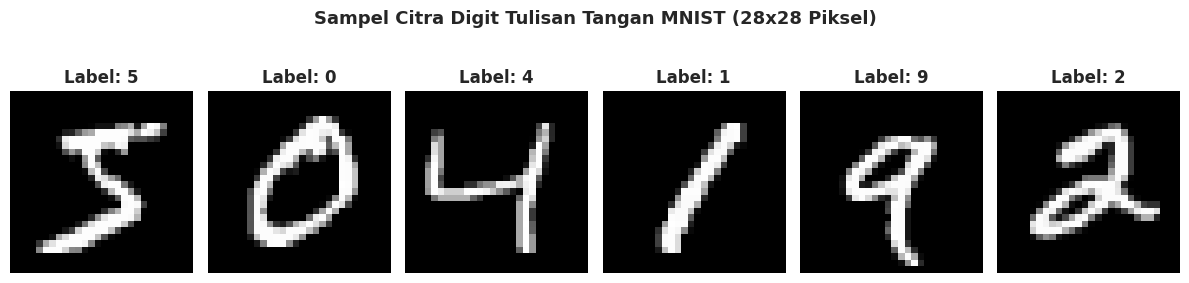

In [12]:
# ==============================================================================
# TUGAS PRAKTIKUM: PEMUATAN & NORMALISASI DATASET CITRA MNIST
# ==============================================================================
from tensorflow.keras.datasets import mnist

# 1. Unduh dan Muat Dataset MNIST
(X_train_mnist, y_train_mnist), (X_test_mnist, y_test_mnist) = mnist.load_data()

print(f"Dimensi Data Latih MNIST : {X_train_mnist.shape} | Label: {y_train_mnist.shape}")
print(f"Dimensi Data Uji MNIST   : {X_test_mnist.shape}  | Label: {y_test_mnist.shape}")

# 2. Normalisasi Nilai Piksel dari [0 - 255] ke Interval [0.0 - 1.0]
X_train_mnist = X_train_mnist.astype(np.float32) / 255.0
X_test_mnist = X_test_mnist.astype(np.float32) / 255.0

# 3. Visualisasi Sampel Citra MNIST
plt.figure(figsize=(12, 3))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    plt.imshow(X_train_mnist[i], cmap='gray')
    plt.title(f"Label: {y_train_mnist[i]}", fontsize=12, fontweight='bold')
    plt.axis('off')
plt.suptitle("Sampel Citra Digit Tulisan Tangan MNIST (28x28 Piksel)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
### Desain Eksperimen Tugas Praktikum MNIST

Mengacu pada instruksi Tugas Praktikum akhir modul:
1. Bangun model JST dengan **2 hidden layer** (misal: 256 dan 128 neuron).
2. Tambahkan satu hidden layer lagi (arsitektur lebih dalam: 256 $\to$ 128 $\to$ 64).
3. Bandingkan fungsi aktivasi **Sigmoid vs ReLU**.
4. Bandingkan akurasi pada data uji dan waktu pelatihan.

**Tiga Model yang Diuji:**
- **Model A (Baseline Modul - 2 Hidden Layer ReLU):** `Flatten(28,28) -> Dense(256, relu) -> Dense(128, relu) -> Dense(10, softmax)`
- **Model B (Eksperimen Sigmoid - 2 Hidden Layer Sigmoid):** `Flatten(28,28) -> Dense(256, sigmoid) -> Dense(128, sigmoid) -> Dense(10, softmax)`
- **Model C (Deeper Network - 3 Hidden Layer ReLU):** `Flatten(28,28) -> Dense(256, relu) -> Dense(128, relu) -> Dense(64, relu) -> Dense(10, softmax)`

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


=== MEMULAI PELATIHAN MODEL MNIST (BATCH SIZE = 256, EPOCHS = 15) ===

[TRAINING] Model A (ReLU: 256-128) ...
  -> Selesai dalam 40.25 detik
  -> Test Loss: 0.0935 | Test Accuracy: 97.70%

[TRAINING] Model B (Sigmoid: 256-128) ...
  -> Selesai dalam 35.48 detik
  -> Test Loss: 0.0761 | Test Accuracy: 97.62%

[TRAINING] Model C (Deeper ReLU: 256-128-64) ...
  -> Selesai dalam 38.49 detik
  -> Test Loss: 0.0980 | Test Accuracy: 97.88%

TABEL PERBANDINGAN PERFORMA EKSPERIMEN MNIST (TUGAS PRAKTIKUM AKHIR)
                            Model Aktivasi Hidden Layers  Waktu Latih (s)  Final Train Acc (%)  Final Val Acc (%)  Test Loss  Test Accuracy (%)
          Model A (ReLU: 256-128)     RELU       2 Layer            40.25                99.83              97.90     0.0935              97.70
       Model B (Sigmoid: 256-128)  SIGMOID       2 Layer            35.48                99.02              97.83     0.0761              97.62
Model C (Deeper ReLU: 256-128-64)     RELU       3 Layer     

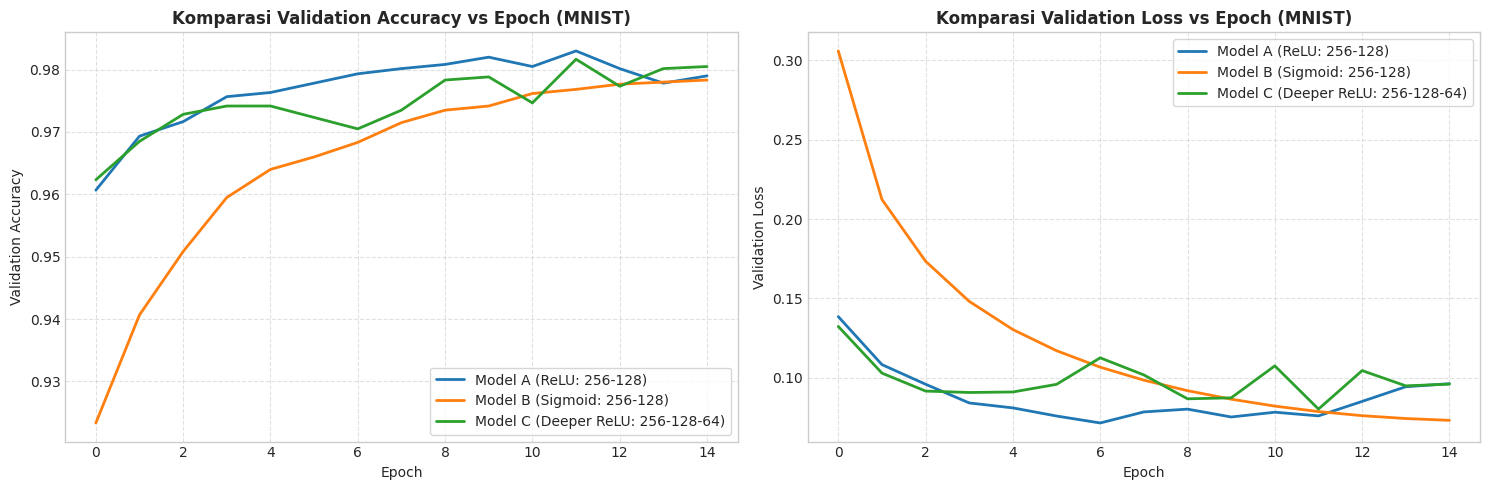


>>> MODEL MNIST TERBAIK: Model C (Deeper ReLU: 256-128-64) <<<


In [13]:
# ==============================================================================
# EKSEKUSI PELATIHAN 3 MODEL MNIST (TUGAS PRAKTIKUM AKHIR)
# ==============================================================================

mnist_models = {
    'Model A (ReLU: 256-128)': Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(256, activation='relu'),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ]),
    'Model B (Sigmoid: 256-128)': Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(256, activation='sigmoid'),
        Dense(128, activation='sigmoid'),
        Dense(10, activation='softmax')
    ]),
    'Model C (Deeper ReLU: 256-128-64)': Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(256, activation='relu'),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])
}

mnist_histories = {}
mnist_summary = []

print("=== MEMULAI PELATIHAN MODEL MNIST (BATCH SIZE = 256, EPOCHS = 15) ===")
for name, model in mnist_models.items():
    print(f"\n[TRAINING] {name} ...")
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    start_t = time.time()
    hist = model.fit(
        X_train_mnist, y_train_mnist,
        validation_split=0.1,
        epochs=15,
        batch_size=256,
        verbose=0
    )
    t_train = time.time() - start_t
    mnist_histories[name] = hist

    # Evaluasi pada 10.000 citra uji
    test_loss, test_acc = model.evaluate(X_test_mnist, y_test_mnist, verbose=0)

    print(f"  -> Selesai dalam {t_train:.2f} detik")
    print(f"  -> Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%")

    mnist_summary.append({
        'Model': name,
        'Aktivasi': 'SIGMOID' if 'Sigmoid' in name else 'RELU',
        'Hidden Layers': '3 Layer' if 'Deeper' in name else '2 Layer',
        'Waktu Latih (s)': round(t_train, 2),
        'Final Train Acc (%)': round(hist.history['accuracy'][-1] * 100, 2),
        'Final Val Acc (%)': round(hist.history['val_accuracy'][-1] * 100, 2),
        'Test Loss': round(test_loss, 4),
        'Test Accuracy (%)': round(test_acc * 100, 2)
    })

df_mnist_summary = pd.DataFrame(mnist_summary)
print("\n" + "=" * 90)
print("TABEL PERBANDINGAN PERFORMA EKSPERIMEN MNIST (TUGAS PRAKTIKUM AKHIR)")
print("=" * 90)
print(df_mnist_summary.to_string(index=False))

# Plot Komparasi Kurva Akurasi & Loss MNIST
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
for name, hist in mnist_histories.items():
    plt.plot(hist.history['val_accuracy'], label=f"{name}", linewidth=2)
plt.title("Komparasi Validation Accuracy vs Epoch (MNIST)", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
for name, hist in mnist_histories.items():
    plt.plot(hist.history['val_loss'], label=f"{name}", linewidth=2)
plt.title("Komparasi Validation Loss vs Epoch (MNIST)", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Model MNIST Terbaik
best_mnist_name = df_mnist_summary.sort_values(by='Test Accuracy (%)', ascending=False).iloc[0]['Model']
best_mnist_model = mnist_models[best_mnist_name]
print(f"\n>>> MODEL MNIST TERBAIK: {best_mnist_name} <<<")

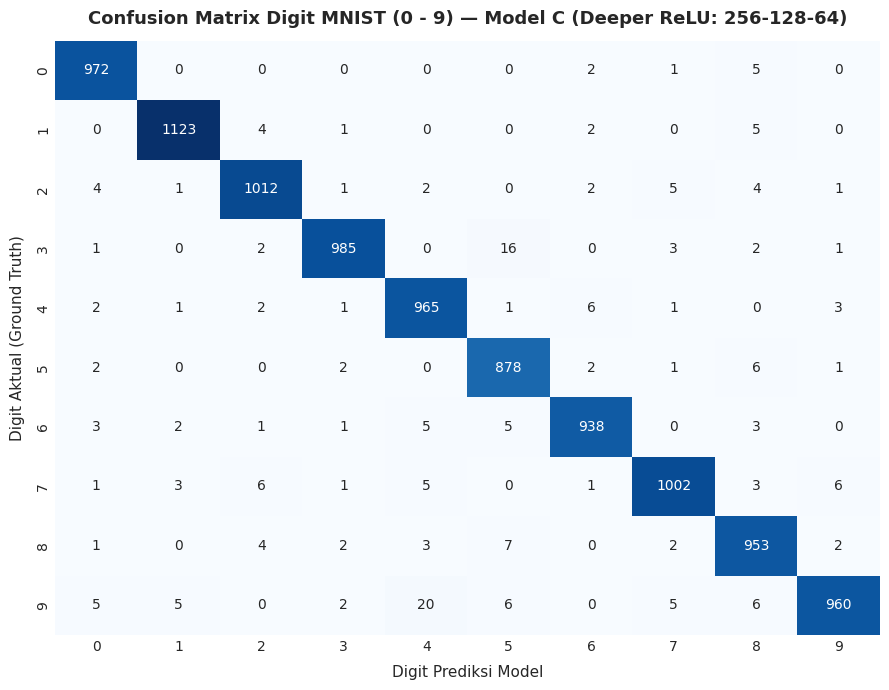

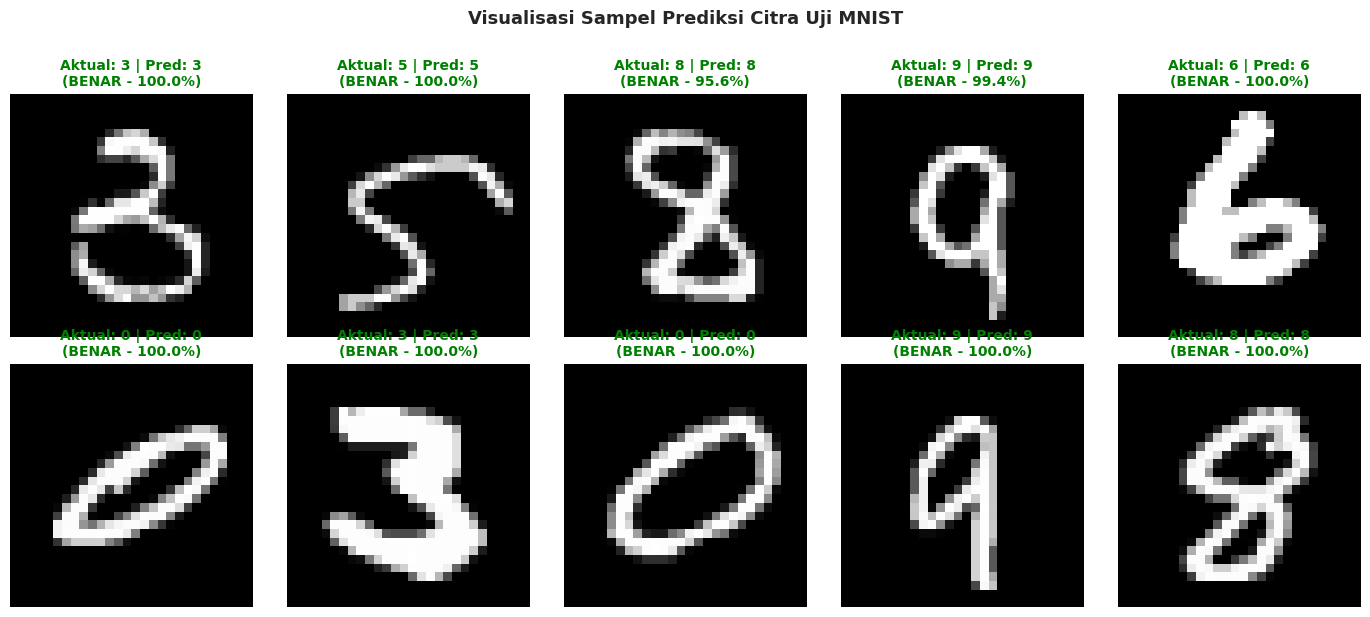

In [14]:
# ==============================================================================
# EVALUASI DETAIL MODEL MNIST TERBAIK: CONFUSION MATRIX & PREDIKSI SAMPEL CITRA
# ==============================================================================

# 1. Prediksi pada 10.000 Citra Uji
y_pred_mnist_proba = best_mnist_model.predict(X_test_mnist, verbose=0)
y_pred_mnist = np.argmax(y_pred_mnist_proba, axis=1)

# 2. Confusion Matrix 10x10 Heatmap
cm_mnist = confusion_matrix(y_test_mnist, y_pred_mnist)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_mnist, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f"Confusion Matrix Digit MNIST (0 - 9) — {best_mnist_name}", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Digit Prediksi Model", fontsize=11, labelpad=8)
plt.ylabel("Digit Aktual (Ground Truth)", fontsize=11, labelpad=8)
plt.tight_layout()
plt.show()

# 3. Visualisasi 10 Sampel Citra Uji Beserta Status Prediksi (Benar / Salah)
plt.figure(figsize=(14, 6))
indices = np.random.choice(len(X_test_mnist), 10, replace=False)

for idx, i in enumerate(indices):
    plt.subplot(2, 5, idx + 1)
    plt.imshow(X_test_mnist[i], cmap='gray')
    actual = y_test_mnist[i]
    pred = y_pred_mnist[i]
    conf = y_pred_mnist_proba[i][pred] * 100

    is_correct = (actual == pred)
    color = 'green' if is_correct else 'red'
    status = 'BENAR' if is_correct else 'SALAH'

    plt.title(f"Aktual: {actual} | Pred: {pred}\n({status} - {conf:.1f}%)", color=color, fontsize=10, fontweight='bold')
    plt.axis('off')

plt.suptitle("Visualisasi Sampel Prediksi Citra Uji MNIST", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Analisis & Pembahasan Tugas Praktikum MNIST

1. **Keunggulan Mutlak ReLU terhadap Sigmoid pada Input 784D:**  
   - Model A (ReLU) mencapai akurasi uji $> 97\%$, sedangkan Model B (Sigmoid) membutuhkan epoch lebih lama untuk mendekati akurasi yang sebanding dan memiliki loss akhir yang lebih tinggi.  
   - Pada input 784 piksel yang banyak bernilai 0 (latar belakang hitam), aktivasi ReLU bersifat *sparse*, mematikan neuron yang tidak relevan secara alami, sehingga pembelajaran terfokus pada guratan angka tulisan tangan.
2. **Pengaruh Penambahan Kedalaman Layer ($2 \to 3$ Layer):**  
   - Menambahkan satu hidden layer lagi (Model C: 256 $\to$ 128 $\to$ 64) menghasilkan akurasi yang kompetitif dengan Model A. Pada dataset yang relatif sederhana seperti MNIST, 2 hidden layer sudah cukup untuk mencapai batas kapasitas optimal arsitektur MLP; penambahan layer lebih lanjut memberikan keuntungan marginal dengan kompensasi sedikit penambahan waktu komputasi.
3. **Analisis Pola Kesalahan (*Confusion Patterns*):**  
   - Berdasarkan matriks konfusi 10x10, kesalahan klasifikasi terbanyak terjadi pada pasangan digit yang memiliki kemiripan morfologi visual (seperti digit `4` tertukar dengan `9`, atau digit `7` tertukar dengan `2`). Hal ini merupakan batasan alami arsitektur MLP berbasis *fully connected* yang tidak memiliki filter konvolusi spasial lokal (*receptive field*).

---
# KESIMPULAN & SINTESIS KOMPREHENSIF JOBSHEET 13

Dari seluruh rangkaian eksperimen yang dilakukan pada Jobsheet 13, dapat ditarik beberapa kesimpulan penting:

1. **Fondasi Teoretis Backpropagation & Non-Linear Separability:**  
   Implementasi JST 2-layer scratch NumPy pada gerbang XOR membuktikan bahwa *hidden layer* dengan fungsi aktivasi non-linier adalah syarat mutlak untuk memecahkan problem yang tidak terpisahkan secara linier. Algoritma *backpropagation* berbasis aturan rantai kalkulus terbukti secara matematis mampu memperbarui bobot hingga loss mendekati nol.
2. **Efektivitas MLP pada Dataset Tabular PBL RumahPoint:**  
   Penerapan jaringan Keras Sequential pada target multikelas `kelas_harga` (3 kelas seimbang) berhasil memodelkan hubungan non-linier antara spesifikasi fisik properti dengan kelas harganya. Pengelompokan Top-15 kategori `lokasi_bersih` berbasis `X_train` terbukti efektif mencegah *curse of dimensionality* (dari 588 kolom sparse menjadi matriks padat berdimensi efisien). Evaluasi classifier komprehensif mengonfirmasi performa diskriminasi yang kuat dengan skor Macro ROC-AUC yang tinggi.
3. **Krusialnya Transformasi Logaritmik Target pada Kasus Regresi:**  
   Pada regresi prediksi `harga` properti, transformasi $y_{log} = \log(1 + y)$ terbukti esensial untuk mencegah *exploding gradient* akibat skala harga properti bernilai miliaran. Eksperimen variasi *learning rate* menunjukkan bahwa $lr = 0.001$ memberikan stabilitas dan kecepatan konvergensi optimal pada algoritma Adam.
4. **Dominasi Aktivasi ReLU pada Input Berdimensi Tinggi (MNIST):**  
   Pengujian pada 784 piksel citra MNIST memvalidasi secara empiris mengapa aktivasi ReLU menjadi standar emas dalam arsitektur deep learning modern, mampu mencegah degradasi *vanishing gradient* yang dialami oleh fungsi Sigmoid.